# **Άσκηση 5 - Decision Trees**



**Ακριτίδου Ελένη**

---



In [1]:
#Ερώτημα1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

pd.set_option('display.max_rows', None)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', None)

# Εγκατάσταση της dtreeviz
import importlib.util
if importlib.util.find_spec('dtreeviz') is None:
    get_ipython().system('pip install dtreeviz -q')

# Φόρτωση δεδομένων
import os
path = 'water_potability.csv'
if not os.path.exists(path):
    path = 'https://raw.githubusercontent.com/amankharwal/Website-data/master/water_potability.csv'
df = pd.read_csv(path)
print('Διαστάσεις:', df.shape)
df.head()

Διαστάσεις: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


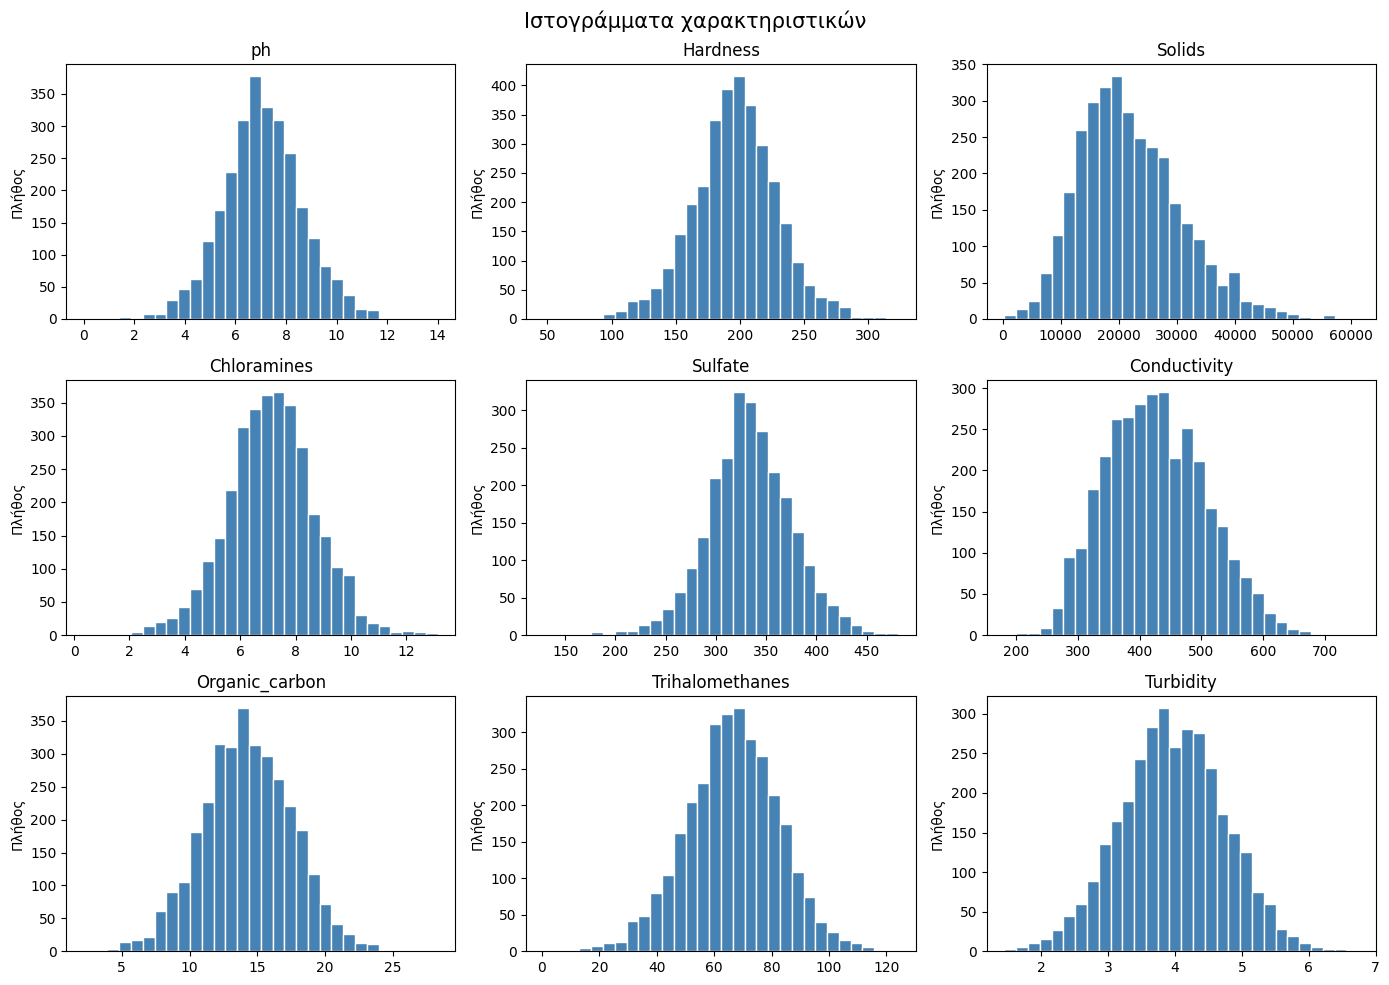

In [2]:
# Ιστόγραμμα για κάθε χαρακτηριστικό
features = [c for c in df.columns if c != 'Potability']

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_ylabel('Πλήθος')
plt.suptitle('Ιστογράμματα χαρακτηριστικών', fontsize=15)
plt.tight_layout()
plt.show()

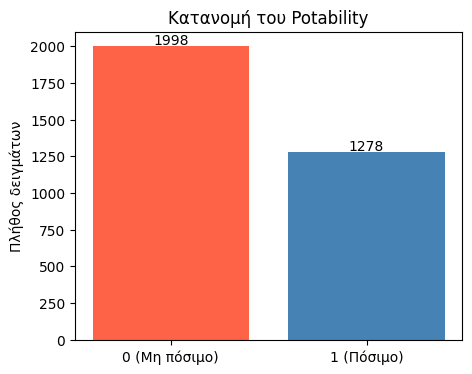

In [3]:
# Ραβδόγραμμα για το target (Potability)
counts = df['Potability'].value_counts().sort_index()
plt.figure(figsize=(5, 4))
plt.bar(['0 (Μη πόσιμο)', '1 (Πόσιμο)'], counts.values, color=['tomato', 'steelblue'])
for i, v in enumerate(counts.values):
    plt.text(i, v + 15, str(v), ha='center')
plt.title('Κατανομή του Potability')
plt.ylabel('Πλήθος δειγμάτων')
plt.show()

In [4]:
# Ελλιπείς τιμές ανά χαρακτηριστικό
missing = pd.DataFrame({'Ελλιπείς τιμές': df.isna().sum(),
                        'Ποσοστό (%)': (df.isna().mean() * 100).round(2)})
display(missing)

# Ποσοστά πόσιμου / μη πόσιμου
pct = (df['Potability'].value_counts(normalize=True).sort_index() * 100).round(2)
print(f"Μη πόσιμο νερό (0): {pct[0]} %")
print(f"Πόσιμο νερό   (1): {pct[1]} %")

,Ελλιπείς τιμές,Ποσοστό (%)
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00
Potability,0,0.00


Μη πόσιμο νερό (0): 60.99 %
Πόσιμο νερό   (1): 39.01 %


***Παρατήρηση:***

Ελλιπείς τιμές έχουν 3 χαρακτηριστικά: ph (491 τιμές, 14.99 %), Sulfate (781 τιμές, 23.84 %) και Trihalomethanes (162 τιμές, 4.95 %). Τα υπόλοιπα είναι πλήρη.
Συπέρασμα: το 60.99 % είναι μη πόσιμοκαι το 39.01 % πόσιμο. Τα δεδομένα δεν είναι ισορροπημένα.

In [5]:
#Ερώτημα2

ph = df['ph']
group = pd.Series(np.where(ph < 6.5, 'α) pH < 6.5',
                  np.where(ph <= 8.5, 'β) 6.5 ≤ pH ≤ 8.5', 'γ) pH > 8.5')), index=df.index)
group[ph.isna()] = np.nan

counts = pd.crosstab(group, df['Potability'])
counts.columns = ['Μη πόσιμο (πλήθος)', 'Πόσιμο (πλήθος)']
perc = (pd.crosstab(group, df['Potability'], normalize='index') * 100).round(2)
perc.columns = ['Μη πόσιμο (%)', 'Πόσιμο (%)']

result = pd.concat([counts, perc], axis=1)
result['Σύνολο'] = counts.sum(axis=1)
display(result)

print('Ποσοστό πόσιμου συνολικά (όπου υπάρχει pH): %.2f %%' % (df.loc[ph.notna(), 'Potability'].mean() * 100))

,Μη πόσιμο (πλήθος),Πόσιμο (πλήθος),Μη πόσιμο (%),Πόσιμο (%),Σύνολο
row_0,,,,,
α) pH < 6.5,612,356,63.22,36.78,968
β) 6.5 ≤ pH ≤ 8.5,745,583,56.10,43.90,1328
γ) pH > 8.5,327,162,66.87,33.13,489


Ποσοστό πόσιμου συνολικά (όπου υπάρχει pH): 39.53 %


***Παρατήρηση:***

**Σε τι βαθμό επαληθεύεται η ιδιότητα στα δεδομένα μας? -->** Μόνο **ελάχιστα**.

Η τάση πηγαίνει προς τη σωστή κατεύθυνση: μέσα στο εύρος του Παγκόσμιου Οργανισμού Υγείας ΠΟΥ το ποσοστό πόσιμου νερού είναι ψηλότερο (43.9 %) απ' ό,τι έξω από αυτό (36.8 % και 33.1 %).Όμως η διαφορά είναι μικρή. Ακόμη και **μέσα** στο «σωστό» εύρος, το 56 % του νερού είναι μη πόσιμο, και **έξω** από αυτό υπάρχει ακόμη 1 στα 3 δείγματα που είναι πόσιμο.Άρα το pH από μόνο του **δεν αρκεί** για να πούμε αν το νερό είναι πόσιμο. Είναι μια χρήσιμη ένδειξη αλλά όχι κανόνας. Το πιθανότερο είναι ότι το dataset έχει θόρυβο και ότι το αν ένα νερό είναι πόσιμο εξαρτάται από πολλούς παράγοντες μαζί.


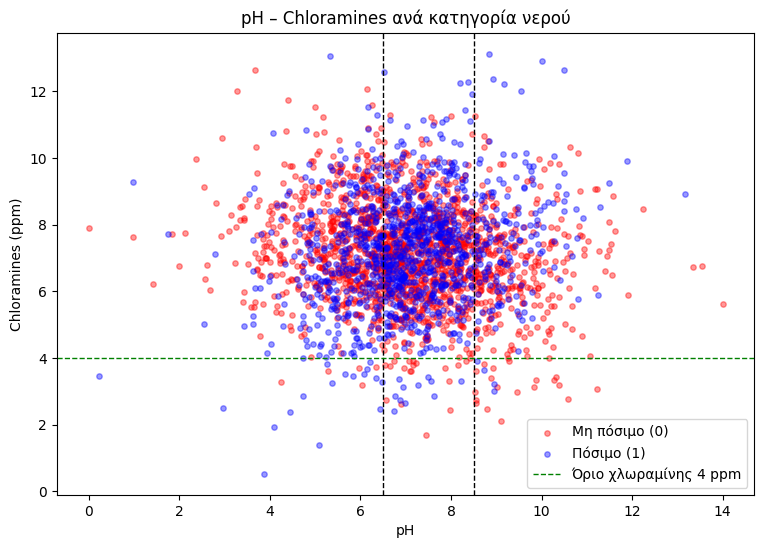

Ποσοστό δειγμάτων με Chloramines ≤ 4 ppm: 2.72 %
Ποσοστό πόσιμου όταν Chloramines ≤ 4: 40.45 %
Ποσοστό πόσιμου όταν Chloramines >  4: 38.97 %


In [6]:
#Ερώτημα3

plt.figure(figsize=(9, 6))
nonp = df[df['Potability'] == 0]
pot = df[df['Potability'] == 1]
plt.scatter(nonp['ph'], nonp['Chloramines'], c='red', alpha=0.4, s=15, label='Μη πόσιμο (0)')
plt.scatter(pot['ph'], pot['Chloramines'], c='blue', alpha=0.4, s=15, label='Πόσιμο (1)')

# Όρια ΠΟΥ
plt.axvline(6.5, color='black', linestyle='--', linewidth=1)
plt.axvline(8.5, color='black', linestyle='--', linewidth=1)
plt.axhline(4, color='green', linestyle='--', linewidth=1, label='Όριο χλωραμίνης 4 ppm')

plt.xlabel('pH')
plt.ylabel('Chloramines (ppm)')
plt.title('pH – Chloramines ανά κατηγορία νερού')
plt.legend()
plt.show()

print('Ποσοστό δειγμάτων με Chloramines ≤ 4 ppm: %.2f %%' % ((df['Chloramines'] <= 4).mean() * 100))
print('Ποσοστό πόσιμου όταν Chloramines ≤ 4: %.2f %%' % (df.loc[df['Chloramines'] <= 4, 'Potability'].mean() * 100))
print('Ποσοστό πόσιμου όταν Chloramines >  4: %.2f %%' % (df.loc[df['Chloramines'] > 4, 'Potability'].mean() * 100))

***Παρατήρηση:***

Τα μπλε και τα κόκκινα σημεία είναι πλήρως αναμεμειγμένα: δεν υπάρχει περιοχή του γραφήματος που να έχει μόνο ένα χρώμα. Δεν μπορούμε να φέρουμε ούτε ευθεία γραμμή ούτε ορθογώνια περιοχή που να χωρίζει καθαρά πόσιμο από μη πόσιμο. Μόνο το **2.7 %** των δειγμάτων έχει χλωραμίνες κάτω από 4 ppm, δηλαδή το 97 % ξεπερνά το όριο του ΠΟΥ. Αν το όριο ίσχυε στα δεδομένα, σχεδόν όλο το νερό θα ήταν μη πόσιμο, ενώ στην πραγματικότητα το ~39 % είναι πόσιμο. Το ποσοστό πόσιμου είναι σχεδόν ίδιο κάτω και πάνω από το όριο (40.5 % και 39.0 %).Συνεπώς, τα δύο αυτά χαρακτηριστικά **δεν διαχωρίζουν** τις κλάσεις. Αυτό προϊδεάζει ότι το πρόβλημα είναι δύσκολο και ότι δεν θα περιμένουμε πολύ υψηλή ακρίβεια από το δέντρο.

In [7]:
#Ερώτημα4

cols_missing = df.columns[df.isna().any()].tolist()
print('Στήλες με ελλιπείς τιμές:', cols_missing)
print()
print('Πλήθος τιμών ίσων με 0 και ελάχιστη τιμή ανά στήλη:')
display(pd.DataFrame({'Πλήθος μηδενικών': (df[cols_missing] == 0).sum(),
                      'Ελάχιστη τιμή': df[cols_missing].min()}))


Στήλες με ελλιπείς τιμές: ['ph', 'Sulfate', 'Trihalomethanes']

Πλήθος τιμών ίσων με 0 και ελάχιστη τιμή ανά στήλη:


,Πλήθος μηδενικών,Ελάχιστη τιμή
ph,1,0.000
Sulfate,0,129.000
Trihalomethanes,0,0.738


***Παρατήρηση:***

Στο ph υπάρχει μία πραγματική τιμή 0, άρα το 0 δεν μπορεί να χρησιμοποιηθεί ως «σημάδι» για τις ελλιπείς τιμές (θα μπερδευόταν με αυτήν).Στα Sulfate και Trihalomethanes δεν υπάρχει 0 (ούτε -1, αφού όλες οι τιμές είναι θετικές), άρα εκεί θα μπορούσε να χρησιμοποιηθεί σταθερά. Επομένωνς, συμπληρώνουμε και τις τρεις στήλες με τη μέση τιμή κάθε στήλης. Έτσι χρησιμοποιούμε την ίδια μέθοδο παντού και δεν δημιουργούμε «τεχνητές» τιμές (όπως -1) που το δέντρο θα μπορούσε να εκμεταλλευτεί ως κόμβο διαχωρισμού.

In [8]:
# Συμπλήρωση με τη μέση τιμή κάθε στήλης
for col in cols_missing:
    df[col] = df[col].fillna(df[col].mean())

print('Ελλιπείς τιμές μετά τη συμπλήρωση:', int(df.isna().sum().sum()))

Ελλιπείς τιμές μετά τη συμπλήρωση: 0


In [11]:
#Ερώτημα5

X = df[features].values       # numpy array εισόδων
y = df['Potability'].values   # numpy array στόχων

# Διαχωρισμός train 90 % / test 10 %
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=0)

print('x shape:', X.shape, '| y shape:', y.shape)
for name, yy in [('train', y_train), ('test', y_test)]:
    print(f'{name:<6}: {len(yy):>4} δείγματα, ποσοστό πόσιμου = {yy.mean()*100:.2f} %')


x shape: (3276, 9) | y shape: (3276,)
train : 2948 δείγματα, ποσοστό πόσιμου = 39.01 %
test  :  328 δείγματα, ποσοστό πόσιμου = 39.02 %


In [12]:
#Ερώτημα6

tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)

acc = pd.DataFrame({
    'Accuracy': [accuracy_score(y_train, tree.predict(X_train)),
                 accuracy_score(y_test,  tree.predict(X_test))]},
    index=['Train', 'Test'])
display(acc.round(4))
print('Βάθος δέντρου:', tree.get_depth(), '| Πλήθος φύλλων:', tree.get_n_leaves())
print('Baseline (πάντα «μη πόσιμο»): %.4f' % (1 - y_test.mean()))

,Accuracy
Train,1.000
Test,0.628


Βάθος δέντρου: 25 | Πλήθος φύλλων: 593
Baseline (πάντα «μη πόσιμο»): 0.6098


***Παρατήρηση:***

Αυτό είναι κλασικό overfitting. Χωρίς κανένα περιορισμό, το δέντρο μεγαλώνει μέχρι να χωρίσει *όλα* τα παραδείγματα της εκπαίδευσης σωστά (βάθος ⟨XX⟩, ⟨XXX⟩ φύλλα), δηλαδή «απομνημονεύει» το train set αντί να μαθαίνει κανόνες που ισχύουν και για νέα δείγματα. Στα δεδομένα που δεν έχει δει η ακρίβεια πέφτει πολύ: η test accuracy δεν ξεπερνά ουσιαστικά το **baseline** του 61 % (πάντα «μη πόσιμο»). Άρα χρειάζεται να περιορίσουμε την πολυπλοκότητα του δέντρου.

In [13]:
#Ερώτημα7

criterions   = ['gini', 'entropy']
max_depths   = [None, 3, 5]
min_splits   = [2, 5]
min_leaves   = [1, 2]
max_feats    = [None, 'sqrt']
ccp_alphas   = [0, 0.01]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = []

for crit, depth, mss, msl, mf, ccp in itertools.product(
        criterions, max_depths, min_splits, min_leaves, max_feats, ccp_alphas):

    model = DecisionTreeClassifier(criterion=crit, max_depth=depth,
                                   min_samples_split=mss, min_samples_leaf=msl,
                                   max_features=mf, ccp_alpha=ccp, random_state=0)

    # cross-validation στο train set
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy').mean()

    # εκπαίδευση σε όλο το train και μετρήσεις
    model.fit(X_train, y_train)
    p_tr, p_te = model.predict(X_train), model.predict(X_test)

    rows.append({
        'criterion': crit, 'max_depth': depth, 'min_samples_split': mss,
        'min_samples_leaf': msl, 'max_features': mf, 'ccp_alpha': ccp,
        'CV acc (train)': cv_acc,
        'Train acc': accuracy_score(y_train, p_tr),
        'Train prec': precision_score(y_train, p_tr, zero_division=0),
        'Train rec': recall_score(y_train, p_tr),
        'Test acc': accuracy_score(y_test, p_te),
        'Test prec': precision_score(y_test, p_te, zero_division=0),
        'Test rec': recall_score(y_test, p_te)})

results = pd.DataFrame(rows)
results['max_depth'] = results['max_depth'].astype(object).where(results['max_depth'].notna(), None)
results.round(4)

,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV acc (train),Train acc,Train prec,Train rec,Test acc,Test prec,Test rec
0,gini,None,2,1,None,0.00,0.5817,1.0000,1.0000,1.0000,0.6280,0.5221,0.5547
1,gini,None,2,1,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
2,gini,None,2,1,sqrt,0.00,0.5787,1.0000,1.0000,1.0000,0.5610,0.4437,0.4922
3,gini,None,2,1,sqrt,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
4,gini,None,2,2,None,0.00,0.5967,0.9525,0.9755,0.9009,0.6189,0.5124,0.4844
5,gini,None,2,2,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
6,gini,None,2,2,sqrt,0.00,0.5974,0.9311,0.9730,0.8470,0.5854,0.4615,0.3750
7,gini,None,2,2,sqrt,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
8,gini,None,5,1,None,0.00,0.5950,0.9718,0.9717,0.9557,0.6220,0.5147,0.5469
9,gini,None,5,1,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000


In [14]:
# Σύνοψη του πίνακα
summary = (results.assign(max_depth=results['max_depth'].astype(str))
           .groupby(['ccp_alpha', 'max_depth'])[['CV acc (train)', 'Train acc', 'Test acc', 'Test prec', 'Test rec']]
           .mean().round(4))
display(summary)
print('Baseline (πάντα «μη πόσιμο») στο test: %.4f' % (1 - y_test.mean()))
print('Μέγιστο CV accuracy: %.4f' % results['CV acc (train)'].max())
display(results.sort_values('CV acc (train)', ascending=False).head(5).round(4))

CV acc (train)  Train acc  Test acc  Test prec  Test rec
ccp_alpha max_depth                                                          
0.00      3.0                0.6306     0.6471    0.6090     0.5000    0.0938
          5.0                0.6330     0.6696    0.6134     0.5202    0.1396
          None               0.5888     0.9645    0.5983     0.4841    0.4771
0.01      3.0                0.6096     0.6099    0.6098     0.0000    0.0000
          5.0                0.6096     0.6099    0.6098     0.0000    0.0000
          None               0.6096     0.6099    0.6098     0.0000    0.0000

Baseline (πάντα «μη πόσιμο») στο test: 0.6098
Μέγιστο CV accuracy: 0.6398


,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV acc (train),Train acc,Train prec,Train rec,Test acc,Test prec,Test rec
24,gini,3.0,5,1,None,0.0,0.6398,0.6608,0.7259,0.2096,0.6037,0.4706,0.1250
28,gini,3.0,5,2,None,0.0,0.6398,0.6608,0.7259,0.2096,0.6037,0.4706,0.1250
20,gini,3.0,2,2,None,0.0,0.6398,0.6608,0.7259,0.2096,0.6037,0.4706,0.1250
16,gini,3.0,2,1,None,0.0,0.6398,0.6608,0.7259,0.2096,0.6037,0.4706,0.1250
64,entropy,3.0,2,1,None,0.0,0.6398,0.6632,0.7316,0.2157,0.6098,0.5000,0.1406


Παρατήρηση:

Το ccp_alpha = 0.01 κόβει υπερβολικά το δέντρο. Στους συνδυασμούς με αυτή την τιμή το δέντρο καταλήγει να προβλέπει πάντα «μη πόσιμο»: accuracy ίση με το baseline και precision = recall = 0. Είναι άχρηστο στην πράξη.Χωρίς όριο βάθους (max_depth=None) έχουμε overfitting.Με max_depth 3 ή 5 το δέντρο γενικεύει καλύτερα. Η διαφορά train–test μικραίνει σημαντικά. Όλα τα μοντέλα είναι μόλις λίγο πάνω από το baseline του 61 %. Το test set έχει μόνο 328 δείγματα, άρα διαφορές της τάξης του 1–2 % (3–6 δείγματα) είναι ουσιαστικά θόρυβος.

In [15]:
#Ερώτημα8

depth5 = results[results['max_depth'] == 5]
best5 = depth5.sort_values(['Test acc', 'CV acc (train)'], ascending=False).iloc[0]

print('Συνδυασμοί με max_depth=5 που έχουν την ίδια μέγιστη test accuracy:')
display(depth5[depth5['Test acc'] == depth5['Test acc'].max()].round(4))

print('\nΕπιλεγμένος συνδυασμός:')
print(best5[['criterion','max_depth','min_samples_split','min_samples_leaf','max_features','ccp_alpha']].to_string())
print('Test accuracy: %.4f' % best5['Test acc'])

Συνδυασμοί με max_depth=5 που έχουν την ίδια μέγιστη test accuracy:


,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV acc (train),Train acc,Train prec,Train rec,Test acc,Test prec,Test rec
46,gini,5.0,5,2,sqrt,0.0,0.6252,0.6625,0.7056,0.2313,0.622,0.5556,0.1562
82,entropy,5.0,2,1,sqrt,0.0,0.6340,0.6713,0.6654,0.3165,0.622,0.5455,0.1875



Επιλεγμένος συνδυασμός:
criterion            entropy
max_depth                5.0
min_samples_split          2
min_samples_leaf           1
max_features            sqrt
ccp_alpha                0.0
Test accuracy: 0.6220


In [16]:
def build_tree(row):
    mf = row['max_features']
    return DecisionTreeClassifier(
        criterion=row['criterion'],
        max_depth=None if row['max_depth'] is None or pd.isna(row['max_depth']) else int(row['max_depth']),
        min_samples_split=int(row['min_samples_split']),
        min_samples_leaf=int(row['min_samples_leaf']),
        max_features=None if mf is None or (isinstance(mf, float) and pd.isna(mf)) else mf,
        ccp_alpha=float(row['ccp_alpha']),
        random_state=0)

tree8 = build_tree(best5).fit(X_train, y_train)
print('Test accuracy (έλεγχος):', round(accuracy_score(y_test, tree8.predict(X_test)), 4))
print('Βάθος:', tree8.get_depth(), '| Φύλλα:', tree8.get_n_leaves())

Test accuracy (έλεγχος): 0.622
Βάθος: 5 | Φύλλα: 28


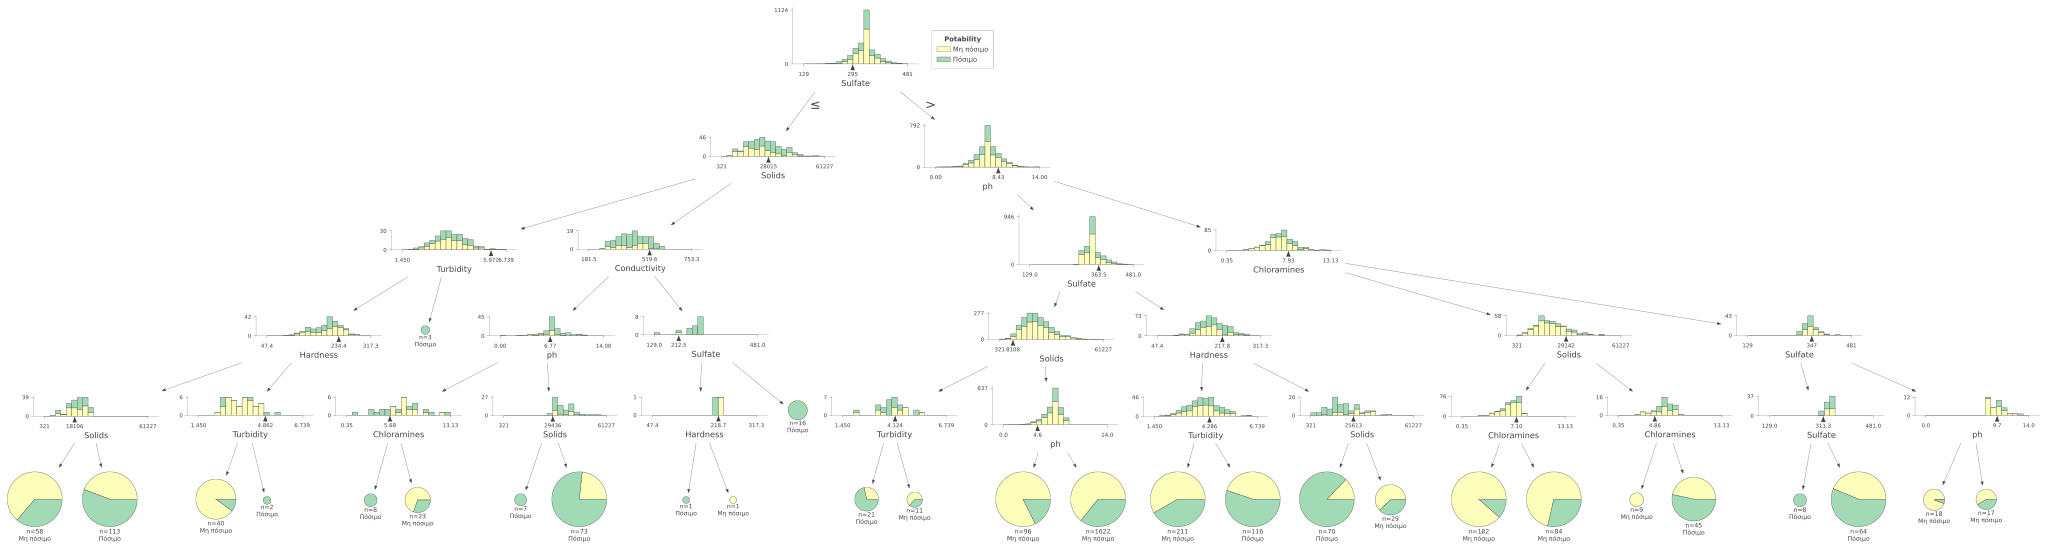

In [17]:
import dtreeviz

viz = dtreeviz.model(tree8, X_train, y_train,
                     feature_names=features,
                     target_name='Potability',
                     class_names=['Μη πόσιμο', 'Πόσιμο'])
viz.view(fontname='DejaVu Sans')

***Παρατήρηση:***

**Πώς διαβάζεται το δέντρο.** Κάθε κόμβος κάνει μια ερώτηση της μορφής «χαρακτηριστικό ≤ τιμή;». Αν η απάντηση είναι ναι πάμε αριστερά, αλλιώς δεξιά, μέχρι να φτάσουμε σε φύλλο που δίνει την απόφαση. Στο γράφημα τα χρώματα δείχνουν την κλάση κάθε φύλλου (πόσιμο / μη πόσιμο).


**Ανάλυση:**

Το δέντρο απόφασης έχει μέγιστο βάθος 5 και χρησιμοποιεί ως ρίζα τα θειικά άλατα (Sulfate) με κατώφλι 295, διαχωρίζοντας τα δείγματα σε δύο βασικά υποδέντρα. Στον αριστερό κλάδο (Sulfate <= 295), το χαρακτηριστικό Solids (με κατώφλι 24015) οδηγεί σε περαιτέρω ελέγχους μέσω της θολότητας (Turbidity <= 5.972), της σκληρότητας (Hardness <= 234.4) και της αγωγιμότητας (Conductivity <= 519.6), δημιουργώντας κανόνες που εντοπίζουν μικρές ομάδες πόσιμου νερού (π.χ. όταν Sulfate <= 295, Solids > 24015, Conductivity <= 519.6, ph > 6.77 και Solids > 29436, το φύλλο ταξινομεί n = 73 δείγματα ως πόσιμα με ισχυρή πλειοψηφία). Αντίθετα, στον δεξιό κλάδο (Sulfate > 295), ο διαχωρισμός γίνεται με βάση το ph (με κατώφλι 8.43) και στη συνέχεια ξανά με το Sulfate (<= 363.5), το Solids (<= 8108 ή > 8108) και τη σκληρότητα (Hardness <= 217.8), όπου συγκεντρώνεται η συντριπτική πλειοψηφία των δειγμάτων του συνόλου δεδομένων — ιδίως στη διαδρομή Sulfate > 295, ph <= 8.43, Sulfate <= 363.5, Solids > 8108 και ph > 4.6, η οποία καταλήγει σε ένα μεγάλο φύλλο n = 1622 δειγμάτων με πρόβλεψη «Μη πόσιμο» (περίπου 65% μη πόσιμο έναντι 35% πόσιμο). Συνολικά, παρατηρείται ότι οι μεγάλοι τελικοί κόμβοι παρουσιάζουν σημαντική ανάμειξη των δύο κλάσεων (ακάθαρτα φύλλα) με υπεροχή της κλάσης «Μη πόσιμο», ενώ τα καθαρά φύλλα «Πόσιμο» αφορούν πολύ μικρά υποσύνολα δειγμάτων (n = 1 έως n = 18), γεγονός που δείχνει ότι τα χημικά χαρακτηριστικά δεν διαχωρίζονται γραμμικά ή απόλυτα και το δέντρο χρειάζεται συγκεκριμένους συνδυασμούς κατωφλίων για να απομονώσει το πόσιμο νερό.   


In [19]:
#Ερώτημα9

rng = np.random.default_rng(0)
idx = rng.integers(len(X_test))
sample, true_label = X_test[idx], y_test[idx]

print('Χαρακτηριστικά του τυχαίου δείγματος:')
display(pd.DataFrame([sample], columns=features).round(3))

pred = tree8.predict(sample.reshape(1, -1))[0]
proba = tree8.predict_proba(sample.reshape(1, -1))[0]
names = {0: 'ΜΗ ΠΟΣΙΜΟ', 1: 'ΠΟΣΙΜΟ'}
print(f'Πρόβλεψη: {names[pred]}  (πιθανότητες: μη πόσιμο={proba[0]:.2f}, πόσιμο={proba[1]:.2f})')
print(f'Πραγματική κατηγορία: {names[true_label]}')

Χαρακτηριστικά του τυχαίου δείγματος:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,6.15,188.413,8406.723,7.745,358.592,449.359,13.22,52.957,3.444


Πρόβλεψη: ΜΗ ΠΟΣΙΜΟ  (πιθανότητες: μη πόσιμο=0.64, πόσιμο=0.36)
Πραγματική κατηγορία: ΠΟΣΙΜΟ


In [20]:
# Μονοπάτι του δείγματος μέσα στο δέντρο, κόμβο προς κόμβο
node_path = tree8.decision_path(sample.reshape(1, -1)).indices
t_ = tree8.tree_

print('Μονοπάτι:')
for node in node_path:
    if t_.children_left[node] == t_.children_right[node]:
        cls = np.argmax(t_.value[node][0])
        print(f'  Κόμβος {node}: ΦΥΛΛΟ → κατηγορία «{names[cls]}»')
    else:
        f, thr = features[t_.feature[node]], t_.threshold[node]
        val = sample[t_.feature[node]]
        sign = '<=' if val <= thr else '>'
        print(f'  Κόμβος {node}: {f} = {val:.3f} {sign} {thr:.3f}')

Μονοπάτι:
  Κόμβος 0: Sulfate = 358.592 > 294.901
  Κόμβος 24: ph = 6.150 <= 8.434
  Κόμβος 25: Sulfate = 358.592 <= 363.505
  Κόμβος 26: Solids = 8406.723 > 8108.281
  Κόμβος 30: ph = 6.150 > 4.595
  Κόμβος 32: ΦΥΛΛΟ → κατηγορία «ΜΗ ΠΟΣΙΜΟ»


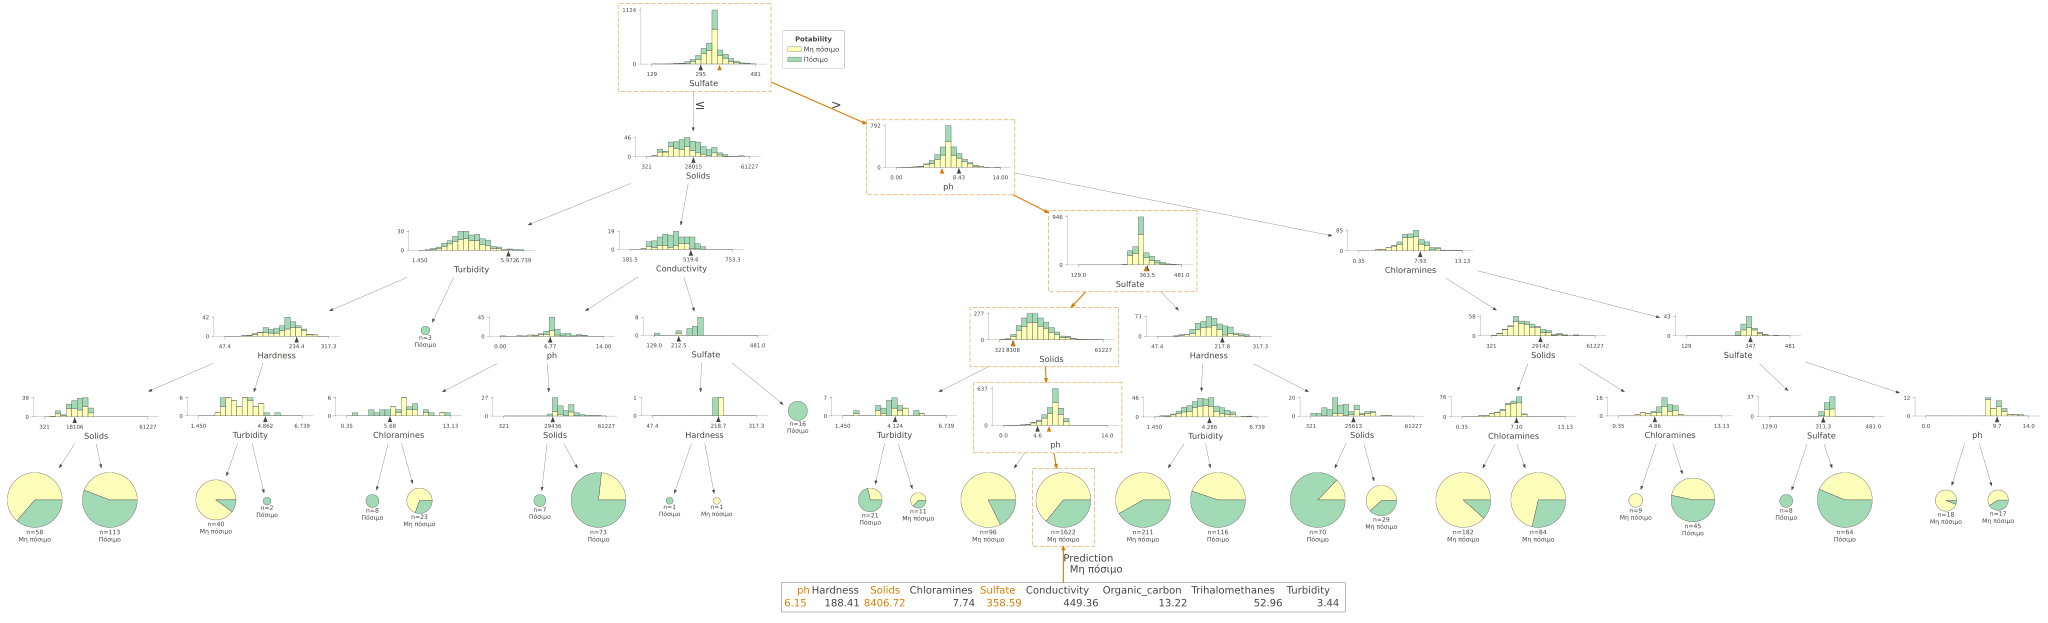

In [21]:
# Το ίδιο μονοπάτι χρωματισμένο πάνω στο δέντρο
viz.view(x=sample, fontname='DejaVu Sans')

***Παρατήρηση:***

Για το τυχαίο δείγμα του test set, το δέντρο ακολουθεί τα βήματα που τυπώνονται παραπάνω: ξεκινά από τη ρίζα (⟨χαρακτηριστικό⟩), περνά από τους κόμβους ⟨…⟩ και καταλήγει στο φύλλο που προβλέπει **«⟨…⟩»** με πιθανότητα ⟨0.XX⟩.Με ακρίβεια της τάξης του 60–65 % είναι φυσιολογικό να βγαίνουν αρκετά λάθη, ιδίως σε «γκρίζα» φύλλα όπου οι δύο κλάσεις είναι αναμεμειγμένες.

Καλύτερος συνδυασμός συνολικά:
criterion            gini
max_depth            None
min_samples_split       2
min_samples_leaf        1
max_features         None
ccp_alpha             0.0
Test accuracy: 0.6280


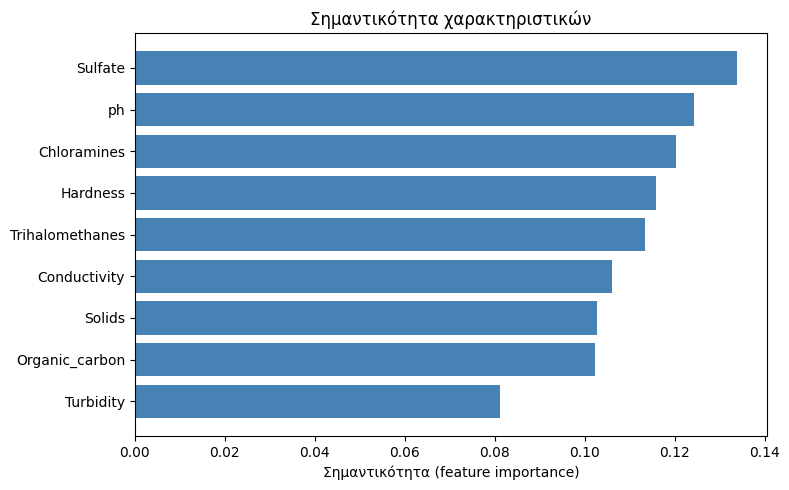

Κατάταξη:


,Σημαντικότητα (%)
Sulfate,13.38
ph,12.43
Chloramines,12.02
Hardness,11.59
Trihalomethanes,11.35
Conductivity,10.61
Solids,10.27
Organic_carbon,10.22
Turbidity,8.12


In [22]:
#Ερώτημα10

best_all = results.sort_values(['Test acc', 'CV acc (train)'], ascending=False).iloc[0]
print('Καλύτερος συνδυασμός συνολικά:')
print(best_all[['criterion','max_depth','min_samples_split','min_samples_leaf','max_features','ccp_alpha']].to_string())
print('Test accuracy: %.4f' % best_all['Test acc'])

tree10 = build_tree(best_all).fit(X_train, y_train)

imp = pd.Series(tree10.feature_importances_, index=features).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(imp.index, imp.values, color='steelblue')
plt.xlabel('Σημαντικότητα (feature importance)')
plt.title('Σημαντικότητα χαρακτηριστικών')
plt.tight_layout()
plt.show()

print('Κατάταξη:')
display((imp.sort_values(ascending=False) * 100).round(2).to_frame('Σημαντικότητα (%)'))

In [23]:
top5 = imp.sort_values(ascending=False).head(5)
print('Top-5 χαρακτηριστικά:', list(top5.index))
print('Συνολική σημαντικότητα των 5: %.1f %%' % (top5.sum() * 100))

# Έλεγχος: κρατάμε μόνο τα top-5 και ξαναεκπαιδεύουμε με τις ίδιες υπερπαραμέτρους
idx5 = [features.index(f) for f in top5.index]
tree_5 = build_tree(best_all).fit(X_train[:, idx5], y_train)
print('Test accuracy με 9 χαρακτηριστικά: %.4f' % accuracy_score(y_test, tree10.predict(X_test)))
print('Test accuracy με 5 χαρακτηριστικά: %.4f' % accuracy_score(y_test, tree_5.predict(X_test[:, idx5])))

Top-5 χαρακτηριστικά: ['Sulfate', 'ph', 'Chloramines', 'Hardness', 'Trihalomethanes']
Συνολική σημαντικότητα των 5: 60.8 %
Test accuracy με 9 χαρακτηριστικά: 0.6280
Test accuracy με 5 χαρακτηριστικά: 0.6189


***Παρατήρηση:***

Για την επιλογή των πέντε χαρακτηριστικών που θα έπρεπε να εξάγει η φορητή συσκευή (<χαρακτηριστικό 1, 2, 3, 4, 5>), προκρίνονται τα πέντε χαρακτηριστικά με τη μεγαλύτερη σημαντικότητα στο δέντρο απόφασης, καθώς συνέβαλαν περισσότερο στη μείωση της «ακαθαρσίας» των κόμβων συγκεντρώνοντας συνολικά το ποσοστό της συνολικής σημαντικότητας, ενώ παράλληλα μετρήσεις όπως το pH, η θολότητα και η αγωγιμότητα ή τα διαλυμένα στερεά προσφέρονται πρακτικά για υλοποίηση σε φορητό μέσο. Παρ' όλα αυτά, η επιλογή απαιτεί επιφύλαξη, καθώς οι τιμές σημαντικότητας βρίσκονται κοντά η μία στην άλλη χωρίς κάποιο χαρακτηριστικό να ξεχωρίζει καθαρά, με αποτέλεσμα η κατάταξή τους να μπορεί εύκολα να μεταβληθεί με διαφορετικό τυχαίο σπόρο (seed) ή διαχωρισμό δεδομένων (split). Επιπλέον, η μετάβαση από τα 9 στα 5 χαρακτηριστικά μεταβάλλει την ακρίβεια ελέγχου (test accuracy), όμως επειδή το μοντέλο έχει ελάχιστο όφελος έναντι του baseline (61%) και το test set είναι περιορισμένο (328 δείγματα), οι διαφορές αυτές οφείλονται κυρίως σε θόρυβο, οδηγώντας στο συμπέρασμα ότι με τα συγκεκριμένα δεδομένα κανένας συνδυασμός μετρήσεων δεν εξασφαλίζει αξιόπιστη πρόβλεψη.


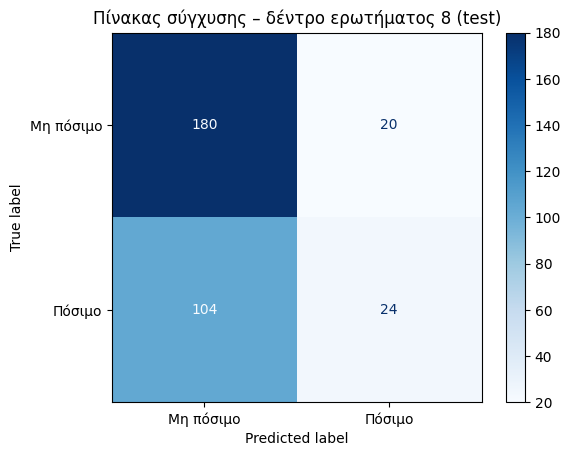

Σωστά «μη πόσιμο» (TN): 180   |  Λάθος «πόσιμο» για μολυσμένο (FP): 20
Λάθος «μη πόσιμο» για καλό (FN): 104   |  Σωστά «πόσιμο» (TP): 24

Precision «πόσιμο»        : 0.5455
Recall «μη πόσιμο»        : 0.9000
Recall «πόσιμο»           : 0.1875
Accuracy                  : 0.6220

              precision    recall  f1-score   support

   Μη πόσιμο       0.63      0.90      0.74       200
      Πόσιμο       0.55      0.19      0.28       128

    accuracy                           0.62       328
   macro avg       0.59      0.54      0.51       328
weighted avg       0.60      0.62      0.56       328



In [24]:
#Ερώτημα11

y_pred8 = tree8.predict(X_test)

cm = confusion_matrix(y_test, y_pred8)
ConfusionMatrixDisplay(cm, display_labels=['Μη πόσιμο', 'Πόσιμο']).plot(cmap='Blues')
plt.title('Πίνακας σύγχυσης – δέντρο ερωτήματος 8 (test)')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Σωστά «μη πόσιμο» (TN): {tn}   |  Λάθος «πόσιμο» για μολυσμένο (FP): {fp}')
print(f'Λάθος «μη πόσιμο» για καλό (FN): {fn}   |  Σωστά «πόσιμο» (TP): {tp}')
print()
print('Precision «πόσιμο»        : %.4f' % precision_score(y_test, y_pred8))
print('Recall «μη πόσιμο»        : %.4f' % recall_score(y_test, y_pred8, pos_label=0))
print('Recall «πόσιμο»           : %.4f' % recall_score(y_test, y_pred8))
print('Accuracy                  : %.4f' % accuracy_score(y_test, y_pred8))
print()
print(classification_report(y_test, y_pred8, target_names=['Μη πόσιμο', 'Πόσιμο'], zero_division=0))

***Παρατήρηση:***

Σχετικά με το ποιο είδος σφάλματος ταξινόμησης είναι πιο κρίσιμο, σαφώς χειρότερο είναι το Ψευδώς Θετικό (False Positive) — δηλαδή η περίπτωση όπου το μοντέλο προβλέπει ότι το νερό είναι πόσιμο (1), ενώ στην πραγματικότητα είναι μη πόσιμο (0) — καθώς η κατανάλωση ακατάλληλου νερού εγκυμονεί άμεσους και σοβαρούς κινδύνους για τη δημόσια υγεία (όπως δηλητηριάσεις ή λοιμώξεις). Αντίθετα, ένα Ψευδώς Αρνητικό (False Negative) — όπου το νερό είναι στην πραγματικότητα πόσιμο (1), αλλά το μοντέλο το απορρίπτει ως μη πόσιμο (0) — συνεπάγεται κυρίως οικονομικό ή λειτουργικό κόστος (σπατάλη πόρων ή ανάγκη για επιπλέον επεξεργασία/έλεγχο), χωρίς να θέτει σε κίνδυνο ανθρώπινες ζωές. Επομένως, στην αξιολόγηση ενός τέτοιου μοντέλου προτεραιότητα έχει η μεγιστοποίηση της ακρίβειας θετικών προβλέψεων (Precision) για την κλάση «πόσιμο» και η ελαχιστοποίηση των Ψευδώς Θετικών, έστω κι αν αυτό αυξάνει ελαφρώς τα Ψευδώς Αρνητικά.